# ODE Integration

`braintools.quad` provides **one-step functions**: each call advances the state by a single time step. You write the loop (usually with `jax.lax.scan` or `brainstate.transform.scan`), so the steppers fit into any model, any PyTree state, and any JAX transformation.

| Family | Steppers | Order |
|---|---|---|
| Euler | `ode_euler_step` | 1 |
| Second order | `ode_rk2_step`, `ode_midpoint_step`, `ode_ralston2_step` | 2 |
| Third order | `ode_rk3_step`, `ode_heun_step` (Heun's third-order method), `ode_ralston3_step`, `ode_ssprk33_step` (strong-stability preserving) | 3 |
| Fourth order | `ode_rk4_step`, `ode_rk4_38_step` | 4 |
| Embedded pairs (`return_error=True`) | `ode_bs32_step`, `ode_rk23_step` (3), `ode_rk45_step`, `ode_rkf45_step`, `ode_dopri5_step`, `ode_rk45_dopri_step` (5), `ode_dopri8_step`, `ode_rk87_dopri_step` (8) | as listed |
| Exponential | `ode_expeuler_step` | 1, exact for linear decoupled dynamics |

This notebook covers:

1. the calling convention;
2. measuring the order of convergence;
3. embedded error estimates and a simple adaptive loop;
4. stiffness and the exponential Euler method;
5. physical units and PyTree states;
6. a Hodgkin–Huxley neuron.

## 1. Setup and Calling Convention

In [1]:
import brainstate
import brainunit as u
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools

jax.config.update("jax_enable_x64", True)  # float64 for the convergence studies

Every ODE stepper has the signature `step(f, y, t, *args)`, where the right-hand side is `f(y, t, *args)`. The step size is **not** an argument: it is read from `brainstate.environ`, either set globally with `brainstate.environ.set(dt=...)` or locally with a context manager.

In [2]:
def decay(y, t, lam):
    return -lam * y

with brainstate.environ.context(dt=0.1):
    y1 = braintools.quad.ode_rk4_step(decay, 1.0, 0.0, 2.0)  # extra args are forwarded to f
print(float(y1), "exact:", np.exp(-0.2))

0.8187333333333333 exact: 0.8187307530779818


To integrate over many steps, scan over the step index. The helper below is used throughout this notebook; it returns the trajectory **including the initial state**, so `ts[i]` and `ys[i]` refer to the same time.

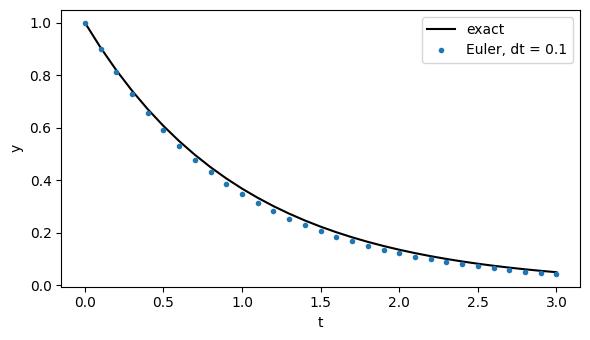

In [3]:
def integrate(step, f, y0, dt, n_steps, *args):
    def body(y, i):
        out = step(f, y, i * dt, *args)
        y_next = out[0] if isinstance(out, tuple) else out  # embedded methods may return (y, err)
        return y_next, y_next

    with brainstate.environ.context(dt=dt):
        _, ys = jax.lax.scan(body, y0, jnp.arange(n_steps))
    ys = jax.tree.map(lambda a, b: jnp.concatenate([jnp.asarray(a)[None], b]), y0, ys)
    return jnp.arange(n_steps + 1) * dt, ys

ts, ys = integrate(braintools.quad.ode_euler_step, decay, jnp.asarray(1.0), 0.1, 30, 1.0)
plt.figure(figsize=(6, 3.5))
plt.plot(ts, np.exp(-ts), "k", label="exact")
plt.plot(ts, ys, "o", ms=3, label="Euler, dt = 0.1")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.tight_layout(); plt.show()

## 2. Order of Convergence

A method of order $p$ has a global error that scales like $\Delta t^p$: halving the step divides the error by $2^p$. Exponential decay is a poor test problem (several methods are unusually accurate on linear equations), so we use a **nonlinear, time-dependent** equation with a known solution:

$$y' = -2 t y^2, \quad y(0) = 1, \qquad y(t) = \frac{1}{1 + t^2}.$$

The measured order is $\log_2(e_{\Delta t} / e_{\Delta t/2})$ for the error at $T = 2$.

In [4]:
f_nl = lambda y, t: -2.0 * t * y ** 2
exact_nl = lambda t: 1.0 / (1.0 + t ** 2)
T = 2.0

def final_error(step, dt):
    n = int(round(T / dt))
    _, ys = integrate(step, f_nl, jnp.asarray(1.0), dt, n)
    return abs(float(ys[-1]) - exact_nl(T))

methods = {
    "ode_euler_step": 1, "ode_midpoint_step": 2, "ode_ralston2_step": 2,
    "ode_rk3_step": 3, "ode_heun_step": 3, "ode_ssprk33_step": 3, "ode_rk4_step": 4, "ode_rk4_38_step": 4,
    "ode_dopri5_step": 5, "ode_dopri8_step": 8,
}
dts = np.array([0.2, 0.1, 0.05, 0.025])
errors = {}
for name, p in methods.items():
    errors[name] = np.array([final_error(getattr(braintools.quad, name), dt) for dt in dts])
    orders = np.log2(errors[name][:-1] / errors[name][1:])
    print(f"{name:20s} expected {p}   measured {np.round(orders, 2)}   error at dt=0.025: {errors[name][-1]:.1e}")

ode_euler_step       expected 1   measured [1.09 1.04 1.02]   error at dt=0.025: 1.6e-03
ode_midpoint_step    expected 2   measured [2.14 2.08 2.04]   error at dt=0.025: 2.1e-05
ode_ralston2_step    expected 2   measured [2.14 2.07 2.03]   error at dt=0.025: 2.8e-05


ode_rk3_step         expected 3   measured [3.24 3.11 3.05]   error at dt=0.025: 2.3e-07
ode_heun_step        expected 3   measured [3.12 3.06 3.03]   error at dt=0.025: 2.2e-07


ode_ssprk33_step     expected 3   measured [3.13 3.07 3.04]   error at dt=0.025: 7.2e-07
ode_rk4_step         expected 4   measured [4.07 4.04 4.02]   error at dt=0.025: 2.4e-09


ode_rk4_38_step      expected 4   measured [3.17 3.81 3.93]   error at dt=0.025: 9.6e-10


ode_dopri5_step      expected 5   measured [5.88 5.53 5.31]   error at dt=0.025: 5.1e-12


ode_dopri8_step      expected 8   measured [ 8.28  8.42 -1.  ]   error at dt=0.025: 5.6e-17


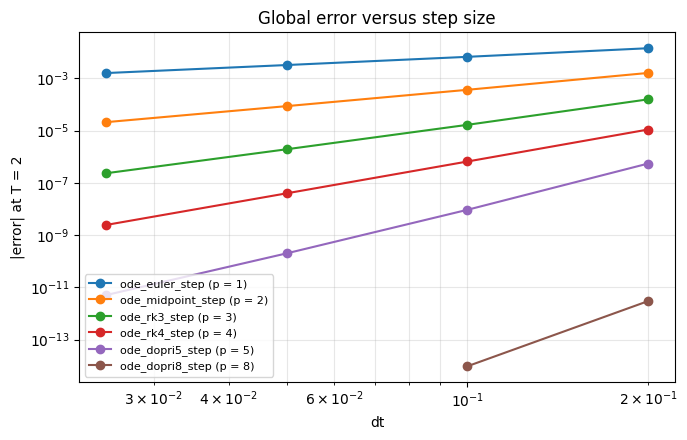

In [5]:
plt.figure(figsize=(7, 4.5))
for name in ["ode_euler_step", "ode_midpoint_step", "ode_rk3_step", "ode_rk4_step", "ode_dopri5_step", "ode_dopri8_step"]:
    e = errors[name]
    keep = e > 1e-15  # below this we only see round-off
    plt.loglog(dts[keep], e[keep], "o-", label=f"{name} (p = {methods[name]})")
plt.xlabel("dt"); plt.ylabel("|error| at T = 2")
plt.title("Global error versus step size")
plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()

Every method reaches its theoretical order (`ode_heun_step` is Heun's *third*-order method, not the second-order trapezoidal predictor–corrector that is often called Heun's method). The 8th-order Dormand–Prince method is at round-off level by `dt = 0.025`, so its last measured ratio is meaningless (printed as a negative order). Convergence studies of high-order methods need large steps. **In float32, no method gets much below $10^{-7}$**, so high orders pay off mainly in float64.

Order is not everything: a 4th-order step costs four evaluations of `f`, Euler one. At equal cost (Euler with a 4× smaller step) RK4 still wins by orders of magnitude here, because the solution is smooth.

## 3. Embedded Error Estimates

The embedded pairs compute two solutions of different order from the same stages. With `return_error=True` they return `(y_next, err)`, where `err` is the difference between the two, an estimate of the **local** error of one step.

In [6]:
with brainstate.environ.context(dt=0.2):
    y1, err = braintools.quad.ode_bs32_step(f_nl, jnp.asarray(1.0), 0.0, return_error=True)
print(f"y(0.2) = {float(y1):.8f}   exact {exact_nl(0.2):.8f}   true error {abs(float(y1) - exact_nl(0.2)):.1e}   estimate {abs(float(err)):.1e}")

y(0.2) = 0.96157600   exact 0.96153846   true error 3.8e-05   estimate 3.6e-04


The estimate measures the error of the **lower-order** solution, while the stepper returns the **higher-order** one ("local extrapolation"). The estimate is therefore conservative: the returned value is usually much more accurate than `err` suggests, as here.

Because the steppers read `dt` from the environment, adaptive stepping is a plain Python loop that changes the context each step. The controller below accepts a step when the error estimate is below the tolerance and adapts `dt` with the standard rule $\Delta t \leftarrow 0.9\,\Delta t\,(\mathrm{tol}/\mathrm{err})^{1/(q+1)}$, where $q$ is the order of the lower-order solution.

In [7]:
def adaptive(step, f, y0, t_end, tol, q, dt=0.1):
    t, y = 0.0, y0
    ts, ys, rejected = [t], [float(y)], 0
    step_jit = jax.jit(lambda y, t, dt: _with_dt(step, f, y, t, dt))
    while t < t_end - 1e-12:
        dt = min(dt, t_end - t)
        y_new, err = step_jit(y, t, dt)
        err = float(jnp.max(jnp.abs(err)))
        if err <= tol:
            t, y = t + dt, y_new
            ts.append(t); ys.append(float(y))
        else:
            rejected += 1
        dt = dt * min(5.0, max(0.2, 0.9 * (tol / max(err, 1e-300)) ** (1.0 / (q + 1))))
    return np.array(ts), np.array(ys), rejected

def _with_dt(step, f, y, t, dt):
    with brainstate.environ.context(dt=dt):
        return step(f, y, t, return_error=True)


# a damped equation whose solution is a sharp front at t = 5:  y = tanh((t - 5) / w)
w = 0.05
front = lambda t: jnp.tanh((t - 5.0) / w)
f_peak = lambda y, t: (1.0 - front(t) ** 2) / w - (y - front(t))
exact_peak = lambda t: np.tanh((t - 5.0) / w)

ts_a, ys_a, rej = adaptive(braintools.quad.ode_bs32_step, f_peak, jnp.asarray(exact_peak(0.0)), 10.0, tol=1e-4, q=2)
err_a = np.max(np.abs(ys_a - exact_peak(ts_a)))
print(f"adaptive BS3(2): {len(ts_a) - 1} accepted steps, {rej} rejected, max error {err_a:.1e}")

for n in [len(ts_a) - 1, 4 * (len(ts_a) - 1), 16 * (len(ts_a) - 1)]:
    tf, yf = integrate(braintools.quad.ode_bs32_step, f_peak, jnp.asarray(exact_peak(0.0)), 10.0 / n, n)
    print(f"fixed step, {n:5d} steps: max error {np.max(np.abs(np.asarray(yf) - exact_peak(tf))):.1e}")

adaptive BS3(2): 47 accepted steps, 16 rejected, max error 7.0e-05


fixed step,    47 steps: max error 1.5e-01


fixed step,   188 steps: max error 1.1e-02


fixed step,   752 steps: max error 1.3e-04


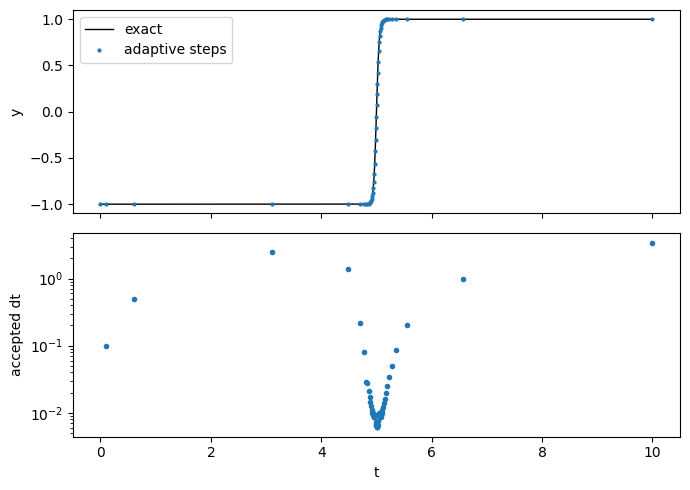

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
tt = np.linspace(0, 10, 2001)
ax[0].plot(tt, exact_peak(tt), "k", lw=1, label="exact")
ax[0].plot(ts_a, ys_a, ".", ms=4, label="adaptive steps")
ax[0].set_ylabel("y"); ax[0].legend()
ax[1].semilogy(ts_a[1:], np.diff(ts_a), ".")
ax[1].set_xlabel("t"); ax[1].set_ylabel("accepted dt")
plt.tight_layout(); plt.show()

The controller takes steps of several time units on the flat parts and steps below 0.01 across the front. A fixed step needs about 16 times more steps for a comparable maximum error, because it must be small everywhere to resolve the front.

A test problem for adaptive stepping should be **well-conditioned**: here the term $-(y - \tanh)$ damps errors. On an equation with $\partial f/\partial y > 0$ the global error grows exponentially no matter how small the local errors are, and a local-error controller cannot help. Note that this loop runs in Python (one jitted step per iteration); inside `jax.lax.scan` the step size has to stay fixed, which is the common case for network simulations.

## 4. Stiffness and the Exponential Euler Method

An equation is **stiff** when it contains time scales much faster than the dynamics you want to resolve. Explicit methods must then use a step below a stability limit set by the fastest scale, even if the solution itself is smooth. A membrane that relaxes with time constant $1/k$ towards a slow input is the simplest example:

$$y' = -k\,(y - \cos t), \qquad k = 1000.$$

After a short transient, $y(t) \approx \cos t$. Explicit Euler is stable only for $k\,\Delta t < 2$, RK4 for $k\,\Delta t < 2.79$.

`ode_expeuler_step` linearizes $f$ around the current state and integrates the linear part exactly:

$$y_{n+1} = y_n + \Delta t\,\varphi(\Delta t\,A)\,f(y_n, t_n), \qquad \varphi(z) = \frac{e^z - 1}{z}, \quad A = \partial f / \partial y.$$

It is first order, but stable for any step on decaying linear dynamics.

In [9]:
k = 1000.0
f_stiff = lambda y, t: -k * (y - jnp.cos(t))
y_ref = lambda t: (k ** 2 * np.cos(t) + k * np.sin(t)) / (k ** 2 + 1)  # the transient has decayed by t = 1

for dt in [0.001, 0.0025, 0.01, 0.05]:
    n = int(round(1.0 / dt))
    row = []
    for name in ["ode_euler_step", "ode_rk4_step", "ode_expeuler_step"]:
        _, ys = integrate(getattr(braintools.quad, name), f_stiff, jnp.asarray(1.0), dt, n)
        row.append(abs(float(ys[-1]) - y_ref(1.0)))
    print(f"dt = {dt:<7} k*dt = {k * dt:5.1f}   Euler {row[0]:9.1e}   RK4 {row[1]:9.1e}   ExpEuler {row[2]:9.1e}")

dt = 0.001   k*dt =   1.0   Euler   2.7e-07   RK4   9.0e-09   ExpEuler   4.9e-04


dt = 0.0025  k*dt =   2.5   Euler   6.8e+63   RK4   1.6e-06   ExpEuler   1.4e-03


dt = 0.01    k*dt =  10.0   Euler   1.1e+90   RK4  6.4e+240   ExpEuler   7.5e-03
dt = 0.05    k*dt =  50.0   Euler   1.5e+29   RK4  5.4e+102   ExpEuler   4.1e-02


Beyond their stability limits, Euler and RK4 blow up (errors of $10^{60}$ and more), while exponential Euler remains stable at 50 times the Euler limit, with an error of $4 \times 10^{-2}$ at $k\,\Delta t = 50$. Within the limits the higher-order methods are more accurate: exponential Euler is only first order (it freezes the forcing $\cos t$ over each step), and its error grows linearly with $\Delta t$.

**Limitation.** $A$ is computed with `brainstate.transform.vector_grad`, which returns the **column sums** of the Jacobian. They equal its diagonal only when each component of $f$ depends on the same component of $y$ (elementwise dynamics, such as a population of uncoupled neurons or gating variables). For coupled variables, call `ode_expeuler_step` once per variable and pass the others as arguments, as in the Hodgkin–Huxley example below. For a coupled stiff part, use the IMEX steppers ({doc}`imex_and_dde_integration`).

## 5. Units and PyTree States

States can be `brainunit` quantities and arbitrary PyTrees. With units, `dt` and `t` must carry time units and `f` must return state units per time; mismatches raise errors instead of silently mixing milliseconds and seconds.

In [10]:
tau, V_rest, R = 10.0 * u.ms, -65.0 * u.mV, 100.0 * u.Mohm

def lif(V, t, I):
    return (V_rest - V + R * I) / tau

with brainstate.environ.context(dt=0.1 * u.ms):
    V = -70.0 * u.mV
    for i in range(500):
        V = braintools.quad.ode_expeuler_step(lif, V, i * 0.1 * u.ms, 0.1 * u.nA)
print("V after 50 ms:", V, "   steady state:", V_rest + R * 0.1 * u.nA)

try:
    with brainstate.environ.context(dt=0.1):  # dt without units
        braintools.quad.ode_rk4_step(lif, -70.0 * u.mV, 0.0, 0.1 * u.nA)
except Exception as e:
    print("unitless dt ->", type(e).__name__)

V after 50 ms: -55.1010692 mV    steady state: -55. mV
unitless dt -> UnitMismatchError


In [11]:
# a PyTree state: excitatory and inhibitory rates of three populations
def rates(state, t, I):
    return {"exc": (-state["exc"] + I) / 10.0, "inh": (-state["inh"] + 0.5 * state["exc"]) / 5.0}

state0 = {"exc": jnp.zeros(3), "inh": jnp.zeros(3)}
ts, traj = integrate(braintools.quad.ode_rk4_step, rates, state0, 0.1, 1000, jnp.array([1.0, 2.0, 3.0]))
print({k: v.shape for k, v in traj.items()})
print("final:", {k: np.round(v[-1], 3) for k, v in traj.items()})

{'exc': (1001, 3), 'inh': (1001, 3)}


final: {'exc': Array([1., 2., 3.], dtype=float64), 'inh': Array([0.5, 1. , 1.5], dtype=float64)}


## 6. Example: the Hodgkin–Huxley Neuron

The Hodgkin–Huxley model has four coupled variables: the membrane potential $V$ and three gating variables $m, h, n$ (units: mV, ms, μF/cm², mS/cm²):

$$C\,V' = I - g_{Na} m^3 h (V - E_{Na}) - g_K n^4 (V - E_K) - g_L (V - E_L), \qquad x' = \alpha_x(V)(1 - x) - \beta_x(V)\,x.$$

We integrate 50 ms with a constant input of 10 μA/cm² and compare spike times with RK4 at `dt = 0.001 ms`. Besides the generic steppers, `hh_expeuler_step` applies exponential Euler **per variable** (each equation is linear in its own variable when the others are frozen), the classic scheme for conductance-based models.

In [12]:
C, gNa, gK, gL, ENa, EK, EL = 1.0, 120.0, 36.0, 0.3, 50.0, -77.0, -54.387

def alpha_beta(V):
    am = 0.1 * (V + 40) / (1 - jnp.exp(-(V + 40) / 10)); bm = 4.0 * jnp.exp(-(V + 65) / 18)
    ah = 0.07 * jnp.exp(-(V + 65) / 20);                  bh = 1.0 / (1 + jnp.exp(-(V + 35) / 10))
    an = 0.01 * (V + 55) / (1 - jnp.exp(-(V + 55) / 10)); bn = 0.125 * jnp.exp(-(V + 65) / 80)
    return (am, bm), (ah, bh), (an, bn)

def dV(V, t, m, h, n, I):
    return (I - gNa * m ** 3 * h * (V - ENa) - gK * n ** 4 * (V - EK) - gL * (V - EL)) / C

def gate(x, t, a, b):
    return a * (1 - x) - b * x

def hh(s, t, I):
    (am, bm), (ah, bh), (an, bn) = alpha_beta(s["V"])
    return {"V": dV(s["V"], t, s["m"], s["h"], s["n"], I),
            "m": gate(s["m"], t, am, bm), "h": gate(s["h"], t, ah, bh), "n": gate(s["n"], t, an, bn)}

def hh_expeuler_step(f, s, t, I):  # same signature as the library steppers; f is unused
    (am, bm), (ah, bh), (an, bn) = alpha_beta(s["V"])
    step = braintools.quad.ode_expeuler_step
    return {"V": step(dV, s["V"], t, s["m"], s["h"], s["n"], I),
            "m": step(gate, s["m"], t, am, bm),
            "h": step(gate, s["h"], t, ah, bh),
            "n": step(gate, s["n"], t, an, bn)}

s0 = {"V": jnp.asarray(-65.0), "m": jnp.asarray(0.053), "h": jnp.asarray(0.596), "n": jnp.asarray(0.318)}
T_hh, I_ext = 50.0, 10.0

def spike_times(ts, V):
    ts, V = np.asarray(ts), np.asarray(V)
    up = np.where((V[:-1] < 0) & (V[1:] >= 0))[0]
    return ts[up] + (0 - V[up]) / (V[up + 1] - V[up]) * (ts[up + 1] - ts[up])  # linear interpolation

ts_ref, ref = integrate(braintools.quad.ode_rk4_step, hh, s0, 0.001, int(T_hh / 0.001), I_ext)
sp_ref = spike_times(ts_ref, ref["V"])
print("reference spike times (ms):", np.round(sp_ref, 3))

reference spike times (ms): [ 1.904 16.825 31.474 46.112]


In [13]:
schemes = {"Euler": braintools.quad.ode_euler_step,
           "RK2": braintools.quad.ode_rk2_step,
           "RK4": braintools.quad.ode_rk4_step,
           "ExpEuler per variable": hh_expeuler_step}
results = {}
for dt in [0.01, 0.05, 0.1, 0.2]:
    for name, step in schemes.items():
        ts_, tr = integrate(step, hh, s0, dt, int(round(T_hh / dt)), I_ext)
        V = np.asarray(tr["V"])
        sp = spike_times(ts_, V)
        if not np.all(np.isfinite(V)):
            msg = "diverged"
        elif len(sp) != len(sp_ref):
            msg = f"{len(sp)} spikes instead of {len(sp_ref)}"
        else:
            msg = f"max spike-time error {np.max(np.abs(sp - sp_ref)):.3f} ms"
        results[(name, dt)] = (np.asarray(ts_), V)
        print(f"dt = {dt:<5} {name:22s} {msg}")

dt = 0.01  Euler                  max spike-time error 0.017 ms


dt = 0.01  RK2                    max spike-time error 0.001 ms


dt = 0.01  RK4                    max spike-time error 0.000 ms


dt = 0.01  ExpEuler per variable  max spike-time error 0.255 ms
dt = 0.05  Euler                  max spike-time error 0.080 ms


dt = 0.05  RK2                    max spike-time error 0.020 ms


...

dt = 0.1   ExpEuler per variable  max spike-time error 2.563 ms


dt = 0.2   Euler                  diverged


dt = 0.2   RK2                    diverged


dt = 0.2   RK4                    diverged


dt = 0.2   ExpEuler per variable  3 spikes instead of 4


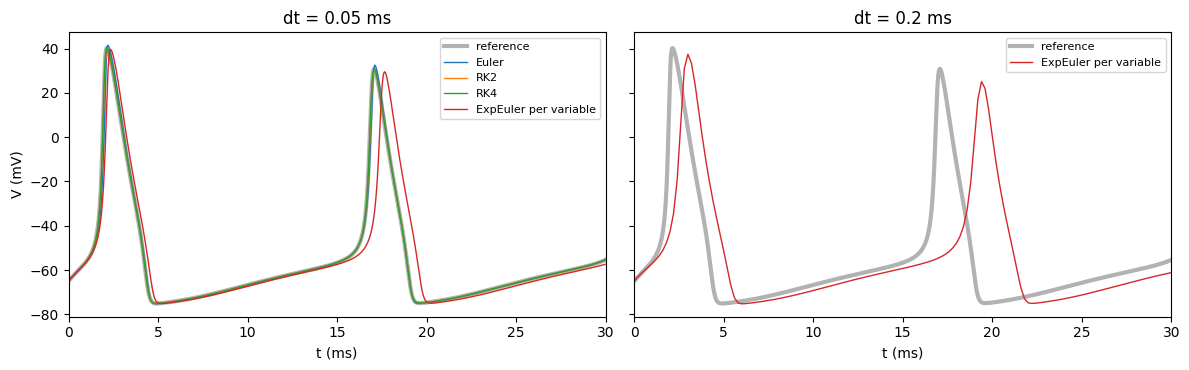

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, dt in zip(ax, [0.05, 0.2]):
    a.plot(ts_ref, ref["V"], "k", lw=3, alpha=0.3, label="reference")
    for color, name in zip(["C0", "C1", "C2", "C3"], schemes):
        ts_, V = results[(name, dt)]
        if np.all(np.isfinite(V)) and np.max(np.abs(V)) < 200:  # skip diverged runs
            a.plot(ts_, V, color=color, lw=1, label=name)
    a.set_title(f"dt = {dt} ms"); a.set_xlabel("t (ms)"); a.set_xlim(0, 30); a.legend(fontsize=8)
ax[0].set_ylabel("V (mV)")
plt.tight_layout(); plt.show()

The results show the trade-off:

- with small steps RK4 is the most accurate method by far, and per-variable exponential Euler is *less* accurate than plain Euler (it is first order with a larger error constant: 0.25 ms against 0.017 ms at `dt = 0.01`, both halving with the step);
- from `dt = 0.1 ms` on, all explicit Runge–Kutta methods diverge because the sodium activation $m$ is stiff during a spike, while exponential Euler keeps running. At `dt = 0.2 ms` it loses a spike, so a stable result is not automatically an accurate one.

For conductance-based models this makes exponential Euler a robust default for large networks with coarse steps, and RK4 (or RK2) with `dt ≲ 0.05 ms` the choice when spike timing matters.

## Summary

- Steppers advance one step: `step(f, y, t, *args)` with `f(y, t, *args)`; `dt` comes from `brainstate.environ`. You write the loop, typically with `jax.lax.scan`.
- All fixed-step methods reach their nominal order on a nonlinear test problem; check convergence in float64, with steps large enough to stay above round-off.
- Embedded pairs return `(y, err)` with `return_error=True`. The estimate refers to the lower-order solution, so it is conservative for the returned value; it is enough to drive an adaptive loop in Python.
- On stiff problems explicit methods need $\Delta t$ below a stability limit. `ode_expeuler_step` removes the limit for elementwise linear decay; for coupled variables, apply it per variable.
- States may be PyTrees and `brainunit` quantities; units are checked at every step.